In [1]:
from pathlib import Path
import math
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import yaml

# Defaults to the data path from the HDF5 inspection; override if needed.
DATA_ROOT = Path(
    os.environ.get("TELLURICS_DATA")
)
H5_PATH = DATA_ROOT / "telluric_timeseries/telluric_templates_nights.h5"

# Find the experiment manifest even when the notebook kernel starts in tests/.
for _directory in (Path.cwd(), *Path.cwd().parents):
    candidate = _directory / "experiments" / "experiment.yaml"
    if candidate.is_file():
        EXPERIMENT_YAML = candidate
        break
else:
    raise FileNotFoundError("Could not find experiments/experiment.yaml from the current directory.")

if not H5_PATH.is_file():
    raise FileNotFoundError(f"HDF5 labels file not found: {H5_PATH}")
print(f"HDF5: {H5_PATH}\nConfig: {EXPERIMENT_YAML}")


HDF5: /home/mvasist/data/Tellurics_data/telluric_timeseries/telluric_templates_nights.h5
Config: /home/mvasist/Tellurics/experiments/experiment.yaml


In [2]:
with h5py.File(H5_PATH, "r") as hf:
    label_dataset = hf["labels"]
    raw_labels = np.asarray(label_dataset[...])
    stored_columns = label_dataset.attrs["columns"]

label_columns = [
    column.decode("utf-8") if isinstance(column, bytes) else str(column)
    for column in stored_columns
]
if raw_labels.shape[-1] != len(label_columns):
    raise ValueError(
        f"Label data has {raw_labels.shape[-1]} columns, but metadata lists "
        f"{len(label_columns)}: {label_columns}"
    )

# Flatten any night/frame dimensions; frame and night indices are not analyzed.
labels = raw_labels.reshape(-1, raw_labels.shape[-1])
index_columns = {"flat_index", "series_index", "frame_index"}
parameter_columns = [column for column in label_columns if column not in index_columns]
column_index = {name: index for index, name in enumerate(label_columns)}
print(f"Loaded {len(labels):,} label rows; parameters: {len(parameter_columns)}")


Loaded 730,000 label rows; parameters: 17


In [3]:
label_columns, raw_labels.shape, label_dataset, 
column_index

{'flat_index': 0,
 'series_index': 1,
 'frame_index': 2,
 'time_hours': 3,
 'pressure': 4,
 'temperature': 5,
 'humidity': 6,
 'angle': 7,
 'airmass': 8,
 'co2': 9,
 'o3': 10,
 'n2o': 11,
 'co': 12,
 'ch4': 13,
 'o2': 14,
 'no': 15,
 'so2': 16,
 'no2': 17,
 'nh3': 18,
 'hno3': 19}

In [4]:
with EXPERIMENT_YAML.open() as stream:
    experiment = yaml.safe_load(stream)


from tellurics.data.splits import split_night_indices


train_ids, val_ids, test_ids = split_night_indices(
            len(raw_labels), 
            experiment["data"]["train_fraction"],
            experiment["data"]["val_fraction"],
            experiment["data"]["seed"],
        )

def night2frame(night_ids):
    """Convert night-level indices to frame-level indices."""
    frame_ids = []
    for night_id in night_ids:
        frame_ids.extend(np.where(labels[:, column_index["series_index"]] == night_id)[0])
    return np.asarray(frame_ids, dtype=np.int64)


training_frames = night2frame(train_ids) #, night2frame(val_ids), night2frame(test_ids)

In [11]:
[column_index[name] for name in parameter_columns]

[3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [16]:
# plt.hist(training_frames)
np.shape(labels[:, np.asarray([5, 8])][training_frames])


(584000, 2)

In [17]:
raw_bounds = experiment["data"]["param_bounds"]
bounds = {}
for name, pair in raw_bounds.items():
    if not isinstance(name, str):
        raise TypeError(f"Parameter bound key must be quoted in YAML: {name!r}")
    bounds[name] = tuple(map(float, pair))

missing_bounds = [name for name in parameter_columns if name not in bounds]
if missing_bounds:
    raise KeyError(f"No experiment.yaml bounds for HDF5 parameters: {missing_bounds}")

values = labels[:, [column_index[name] for name in parameter_columns]][training_frames].astype(np.float64)
print(np.shape(values))
range_report = {}
for index, name in enumerate(parameter_columns):
    column = values[:, index]
    finite = np.isfinite(column)
    low, high = bounds[name]
    below = int(np.count_nonzero(finite & (column < low)))
    above = int(np.count_nonzero(finite & (column > high)))
    observed_min = float(np.min(column[finite])) if finite.any() else np.nan
    observed_max = float(np.max(column[finite])) if finite.any() else np.nan
    range_report[name] = {
        "observed_min": observed_min,
        "configured_min": low,
        "configured_max": high,
        "observed_max": observed_max,
        "below_bound": below,
        "above_bound": above,
        "non_finite": int((~finite).sum()),
        "normalized_min": (observed_min - low) / (high - low),
        "normalized_max": (observed_max - low) / (high - low),
    }

print("parameter      observed min     observed max    configured range      normalized min/max") #     out of bounds  
for name, row in range_report.items():
    print(
        f"{name:12} {row['observed_min']:16.7g}   "
        f"{row['observed_max']:16.7g}   "
        f"[{row['configured_min']:.7g}, {row['configured_max']:.7g}]             "
        # f"{row['below_bound'] + row['above_bound']:5d} "
        # f"({row['below_bound']} below, {row['above_bound']} above)   "
        f"[{row['normalized_min']:.5g}, {row['normalized_max']:.5g}]                                         "
    )

out_of_bounds = {
    name: row for name, row in range_report.items()
    if row["below_bound"] or row["above_bound"] or row["non_finite"]
}
print("\nParameters with out-of-bound or non-finite values:")
print(out_of_bounds if out_of_bounds else "None")


(584000, 17)
parameter      observed min     observed max    configured range      normalized min/max
time_hours                  0                  6   [0, 6]             [0, 1]                                         
pressure             738.4222           749.2171   [600, 850]             [0.55369, 0.59687]                                         
temperature          274.4713           295.8911   [233.15, 318.15]             [0.48613, 0.73813]                                         
humidity          0.001904529           84.23626   [0, 100]             [1.9045e-05, 0.84236]                                         
angle              0.02684384           59.99975   [0, 90]             [0.00029826, 0.66666]                                         
airmass                     1           1.999985   [1, 2]             [1.1921e-07, 0.99998]                                         
co2                  411.6655           443.6367   [420, 435]             [-0.55563, 1.5758]            

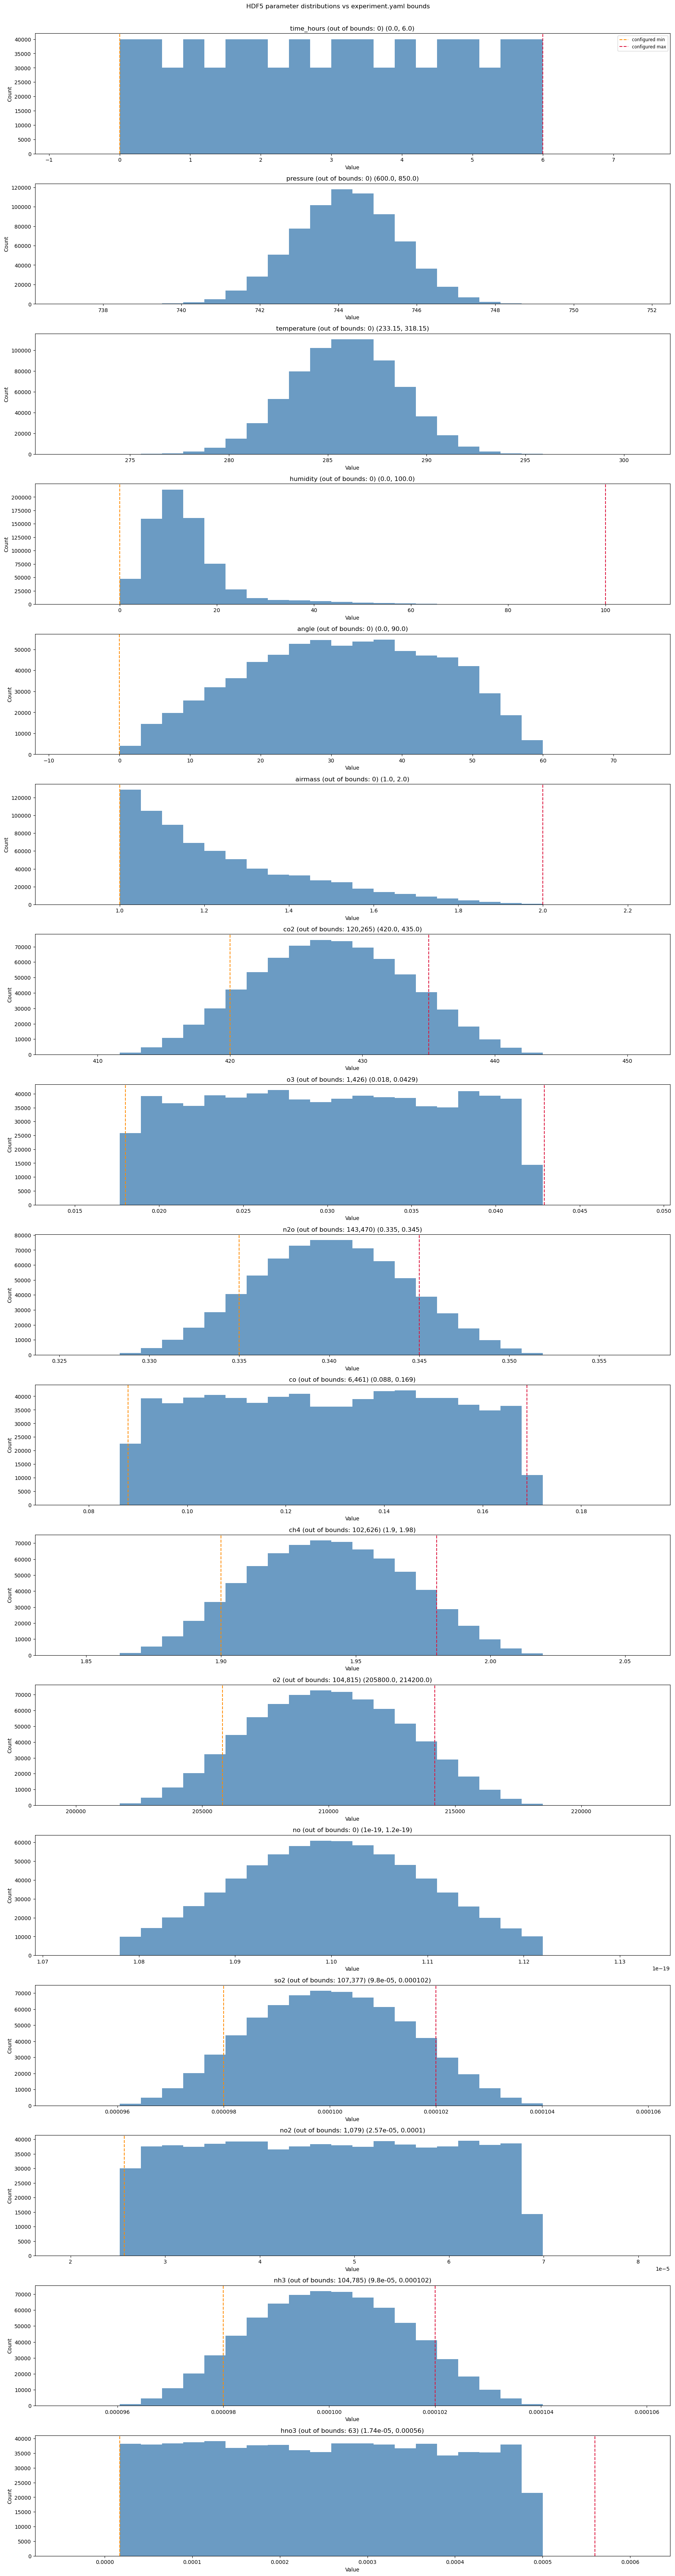

In [18]:
ncols = 1
nrows = math.ceil(len(parameter_columns) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
axes = np.asarray(axes).reshape(-1)


for axis, name in zip(axes, parameter_columns):
    data = labels[:, column_index[name]].astype(np.float64)
    data = data[np.isfinite(data)]
    low, high = bounds[name]

    axis.hist(data, bins=20, color="steelblue", alpha=0.8)
    axis.set_xlim(min(data) - 0.2 * (max(data) - min(data)), max(data) + 0.3 * (max(data) - min(data)))

    axis.axvline(low, color="darkorange", linestyle="--", label="configured min")
    axis.axvline(high, color="crimson", linestyle="--", label="configured max")
    out_count = int(range_report[name]["below_bound"] + range_report[name]["above_bound"])
    axis.set_title(f"{name} (out of bounds: {out_count:,}) {bounds[name]}")
    axis.set_xlabel("Value")
    axis.set_ylabel("Count")

for axis in axes[len(parameter_columns):]:
    axis.set_visible(False)
axes[0].legend(fontsize="small")
fig.suptitle("HDF5 parameter distributions vs experiment.yaml bounds", y=1.002)
fig.tight_layout()
plt.show()


In [19]:
## Configured bounds such that each parameter is between [0, 1]

for i, name in zip(range(values.shape[1]), parameter_columns):
    data = labels[:, column_index[name]].astype(np.float64)
    data = data[np.isfinite(data)]
    print(name, ":", min(data) - 0.1 * (max(data) - min(data)), max(data) + 0.1 * (max(data) - min(data))) #, bounds[parameter_columns[i]], parameter_columns[i])


time_hours : -0.6000000000000001 6.6
pressure : 737.3426879882812 750.2965942382813
temperature : 272.32936401367186 298.0331237792969
humidity : -8.715698910484207 95.87734991426987
angle : -5.970446596667171 65.99703866876662
airmass : 0.9000016689300537 2.099983072280884
co2 : 408.4684143066406 446.8337707519531
o3 : 0.01513712964951992 0.045335124060511586
n2o : 0.3260061711072922 0.3542255491018295
co : 0.07766321375966072 0.18086182251572608
ch4 : 1.846697735786438 2.035217118263245
o2 : 200057.7171875 220155.6734375
no : 1.0736002179614578e-19 1.1263999060931478e-19
so2 : 9.524409761070274e-05 0.00010481412682565861
no2 : 2.0722221779578832e-05 7.440558529197006e-05
nh3 : 9.524373817839659e-05 0.00010483894802746364
hno3 : -3.1255248541128824e-05 0.000548805031212396


In [ ]:
# The MinMax scaler raises when `below_bound` or `above_bound` is nonzero.
# normalized_min/max outside [0, 1] identify how far the data exceed bounds.
sorted(
    range_report.items(),
    key=lambda item: item[1]["below_bound"] + item[1]["above_bound"],
    reverse=True,
)[:10]


[('n2o',
  {'observed_min': 0.3283577859401703,
   'configured_min': 0.335,
   'configured_max': 0.345,
   'observed_max': 0.3518739342689514,
   'below_bound': 70044,
   'above_bound': 73681,
   'non_finite': 0,
   'normalized_min': -0.6642214059829763,
   'normalized_max': 1.6873934268951474}),
 ('co2',
  {'observed_min': 411.66552734375,
   'configured_min': 420.0,
   'configured_max': 435.0,
   'observed_max': 443.6327209472656,
   'below_bound': 58763,
   'above_bound': 62556,
   'non_finite': 0,
   'normalized_min': -0.5556315104166667,
   'normalized_max': 1.5755147298177083}),
 ('so2',
  {'observed_min': 9.60416000452824e-05,
   'configured_min': 9.8e-05,
   'configured_max': 0.000102,
   'observed_max': 0.00010401662439107895,
   'below_bound': 51298,
   'above_bound': 55591,
   'non_finite': 0,
   'normalized_min': -0.4895999886794005,
   'normalized_max': 1.5041560977697372}),
 ('nh3',
  {'observed_min': 9.604333899915218e-05,
   'configured_min': 9.8e-05,
   'configured_max